# **FleetGuard — Phase 1: FD001 Data Exploration & Preparation**
**Dataset**: NASA C-MAPSS FD001 (TXT)
**Goal**: validate the raw files, construct Remaining Useful Life (RUL) labels, split training engines without leakage, and produce initial exploratory plots.

## 0. Setup
Expected folder layout:

```
data/
└── raw/
    ├── train_FD001.txt
    ├── test_FD001.txt
    └── RUL_FD001.txt
```
If using Colab, upload the three FD001 files when prompted. If using Google Drive, mount Drive and set DATA_DIR to the folder containing the files.

In [1]:
from pathlib import Path
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
RUL_CAP = 125  # common piecewise-linear RUL target cap; retain uncapped labels too

# Colab upload option:
try:
    from google.colab import files
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Option A: upload files directly in Colab.
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    DATA_DIR = Path("/content")
else:
    # Option B: local Jupyter/VS Code. Change this path if needed.
    DATA_DIR = Path("data/raw")

# If files are already in a different directory, change DATA_DIR above.
print("Data directory:", DATA_DIR.resolve())

Saving RUL_FD001.txt to RUL_FD001 (1).txt
Saving test_FD001.txt to test_FD001 (1).txt
Saving train_FD001.txt to train_FD001 (1).txt
Data directory: /content


## 1. Define the FD001 schema and load files

In [3]:
COLUMN_NAMES = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i:02d}" for i in range(1, 22)]
)

TRAIN_PATH = DATA_DIR / "train_FD001.txt"
TEST_PATH = DATA_DIR / "test_FD001.txt"
RUL_PATH = DATA_DIR / "RUL_FD001.txt"

for path in [TRAIN_PATH, TEST_PATH, RUL_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing file: {path}\n"
            "Place train_FD001.txt, test_FD001.txt and RUL_FD001.txt "
            "inside DATA_DIR."
        )

def read_cmapss_txt(path):
    # C-MAPSS TXT files are whitespace-delimited and contain no header.
    df = pd.read_csv(path, sep=r"\s+", header=None, names=COLUMN_NAMES)
    # Some distributions have trailing whitespace that can create empty columns;
    # the explicit names above ensure the expected 26-column schema.
    return df

train_raw = read_cmapss_txt(TRAIN_PATH)
test_raw = read_cmapss_txt(TEST_PATH)
test_rul = pd.read_csv(RUL_PATH, sep=r"\s+", header=None, names=["rul_at_last_cycle"])

print("Train shape:", train_raw.shape)
print("Test shape :", test_raw.shape)
print("Test RUL shape:", test_rul.shape)
display(train_raw.head())

Train shape: (20631, 26)
Test shape : (13096, 26)
Test RUL shape: (100, 1)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Validate data integrity

In [4]:
def validate_dataset(df, name):
    assert df.shape[1] == 26, f"{name}: expected 26 columns, got {df.shape[1]}"
    assert df["engine_id"].notna().all(), f"{name}: missing engine IDs"
    assert df["cycle"].notna().all(), f"{name}: missing cycle values"
    assert (df["cycle"] > 0).all(), f"{name}: cycle values must be positive"
    assert not df.duplicated(["engine_id", "cycle"]).any(), f"{name}: duplicate engine-cycle rows"
    assert df.isna().sum().sum() == 0, f"{name}: missing values found"

    cycles_per_engine = df.groupby("engine_id")["cycle"].agg(["min", "max", "count"])
    assert (cycles_per_engine["min"] == 1).all(), f"{name}: some engines do not start at cycle 1"
    assert (cycles_per_engine["count"] == cycles_per_engine["max"]).all(), (
        f"{name}: non-contiguous cycle sequence detected"
    )
    print(f"{name}: validation passed | engines={df.engine_id.nunique()} | rows={len(df)}")

validate_dataset(train_raw, "TRAIN")
validate_dataset(test_raw, "TEST")

assert len(test_rul) == test_raw["engine_id"].nunique(), (
    "RUL_FD001 row count must equal the number of test engines"
)

print("\nTrain engines:", train_raw.engine_id.nunique())
print("Test engines :", test_raw.engine_id.nunique())
print("Train cycle range:", train_raw.cycle.min(), "to", train_raw.cycle.max())
print("Test cycle range :", test_raw.cycle.min(), "to", test_raw.cycle.max())

TRAIN: validation passed | engines=100 | rows=20631
TEST: validation passed | engines=100 | rows=13096

Train engines: 100
Test engines : 100
Train cycle range: 1 to 362
Test cycle range : 1 to 303


## 3. Construct RUL targets

In [5]:
# Training engines run to failure:
# RUL at cycle t = engine's final cycle - t.
train = train_raw.copy()
train_max_cycle = train.groupby("engine_id")["cycle"].transform("max")
train["rul_uncapped"] = train_max_cycle - train["cycle"]
train["rul"] = train["rul_uncapped"].clip(upper=RUL_CAP)

# Test engines are truncated. RUL_FD001 gives the remaining cycles
# AFTER each test engine's final observed cycle.
test = test_raw.copy()
test_engine_ids = np.sort(test["engine_id"].unique())
test_rul = test_rul.copy()
test_rul["engine_id"] = test_engine_ids

test_max_cycle = test.groupby("engine_id")["cycle"].transform("max")
test = test.merge(test_rul, on="engine_id", how="left", validate="many_to_one")
test["rul_uncapped"] = (
    test["rul_at_last_cycle"] + test_max_cycle - test["cycle"]
)
test["rul"] = test["rul_uncapped"].clip(upper=RUL_CAP)

print("Train RUL range:", train.rul_uncapped.min(), "to", train.rul_uncapped.max())
print("Test RUL range :", test.rul_uncapped.min(), "to", test.rul_uncapped.max())
display(train[["engine_id", "cycle", "rul_uncapped", "rul"]].head())
display(test[["engine_id", "cycle", "rul_at_last_cycle", "rul_uncapped", "rul"]].tail())

Train RUL range: 0 to 361
Test RUL range : 7 to 340


,engine_id,cycle,rul_uncapped,rul
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


,engine_id,cycle,rul_at_last_cycle,rul_uncapped,rul
13091,100,194,20,24,24
13092,100,195,20,23,23
13093,100,196,20,22,22
13094,100,197,20,21,21
13095,100,198,20,20,20


## 4. Engine-wise train/validation split (leakage-safe)

In [6]:
# Split by engine ID, not by individual rows.
# All time steps from an engine stay in exactly one partition.
engine_ids = train["engine_id"].drop_duplicates().to_numpy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

row_indices = np.arange(len(train))
train_idx, val_idx = next(
    splitter.split(row_indices, groups=train["engine_id"].to_numpy())
)

train_split = train.iloc[train_idx].copy().reset_index(drop=True)
val_split = train.iloc[val_idx].copy().reset_index(drop=True)

train_engine_set = set(train_split.engine_id.unique())
val_engine_set = set(val_split.engine_id.unique())

assert train_engine_set.isdisjoint(val_engine_set), "Engine leakage detected!"

print(f"Training partition: {len(train_split):,} rows, {len(train_engine_set)} engines")
print(f"Validation partition: {len(val_split):,} rows, {len(val_engine_set)} engines")
print("Engine overlap:", len(train_engine_set.intersection(val_engine_set)))

Training partition: 16,561 rows, 80 engines
Validation partition: 4,070 rows, 20 engines
Engine overlap: 0


## 5. Basic dataset profile

In [7]:
sensor_cols = [f"sensor_{i:02d}" for i in range(1, 22)]
setting_cols = [f"setting_{i}" for i in range(1, 4)]

profile = pd.DataFrame({
    "dataset": ["train", "validation", "test"],
    "rows": [len(train_split), len(val_split), len(test)],
    "engines": [
        train_split.engine_id.nunique(),
        val_split.engine_id.nunique(),
        test.engine_id.nunique()
    ],
    "mean_cycles_per_engine": [
        train_split.groupby("engine_id").size().mean(),
        val_split.groupby("engine_id").size().mean(),
        test.groupby("engine_id").size().mean()
    ]
})
display(profile)

print("Missing values (train):", int(train.isna().sum().sum()))
print("Constant sensor columns:")
constant_sensors = [
    c for c in sensor_cols if train[c].nunique() <= 1
]
print(constant_sensors if constant_sensors else "None")

,dataset,rows,engines,mean_cycles_per_engine
0,train,16561,80,207.0125
1,validation,4070,20,203.5000
2,test,13096,100,130.9600


Missing values (train): 0
Constant sensor columns:
['sensor_01', 'sensor_05', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


## 6. Exploratory plots

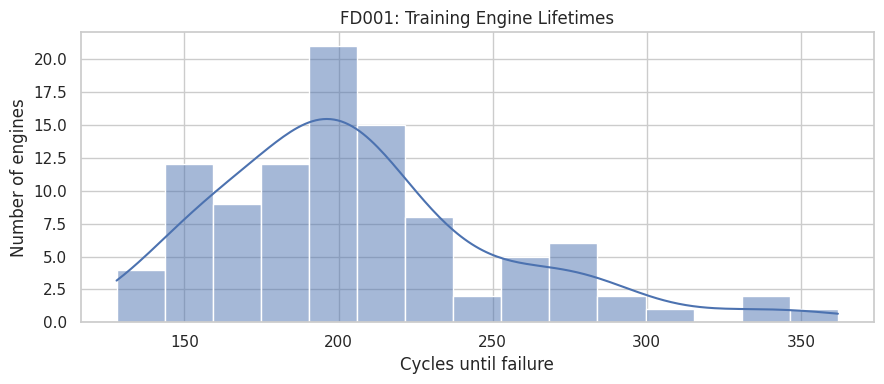

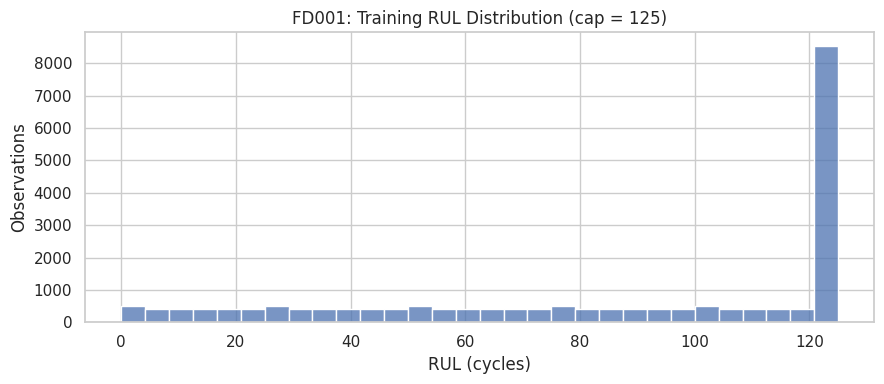

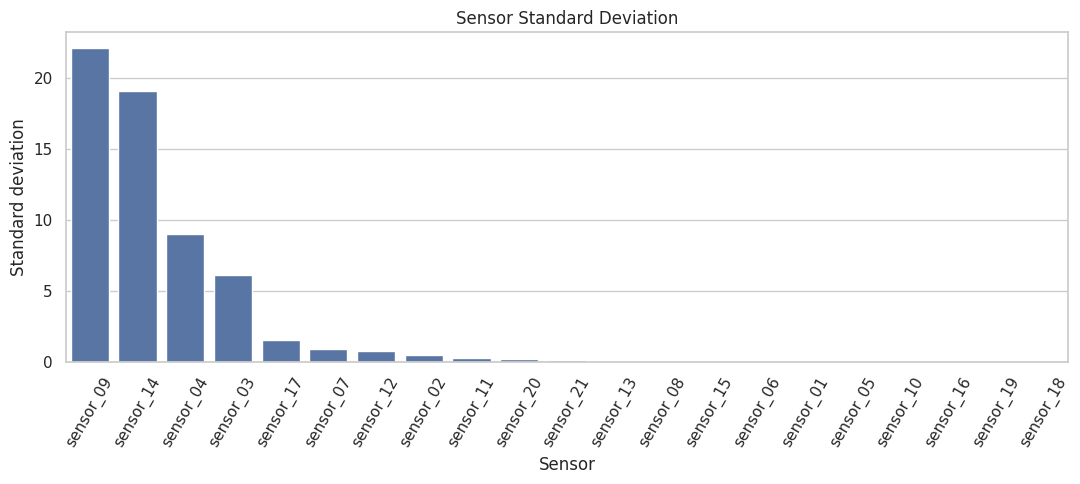

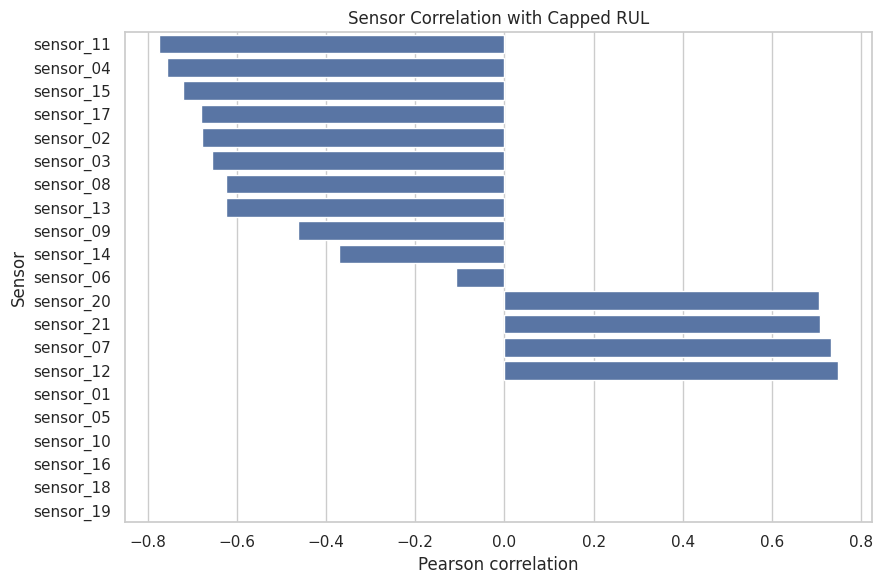

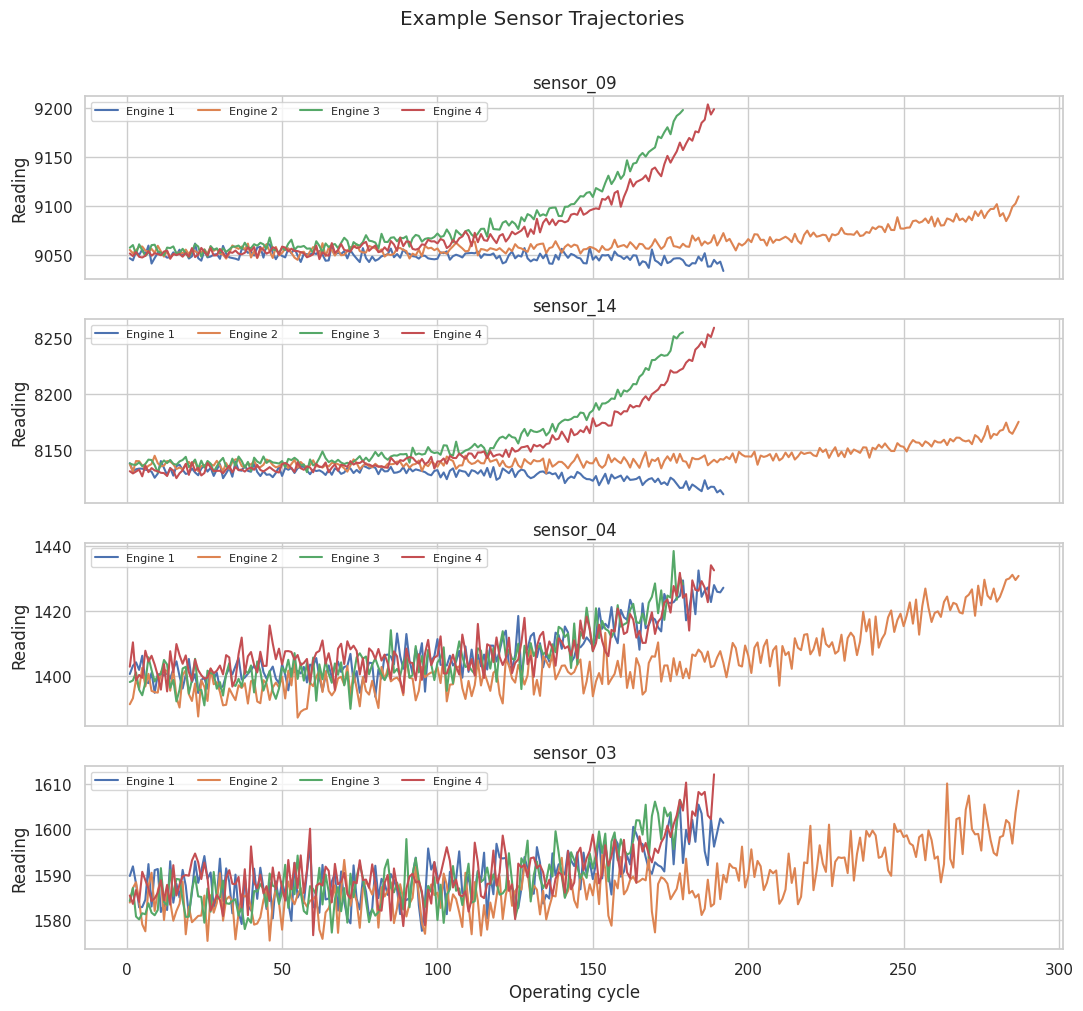

In [8]:
sns.set_theme(style="whitegrid")

# 6.1 Distribution of engine lifetimes
engine_lifetimes = train_raw.groupby("engine_id")["cycle"].max()
plt.figure(figsize=(9, 4))
sns.histplot(engine_lifetimes, bins=15, kde=True)
plt.title("FD001: Training Engine Lifetimes")
plt.xlabel("Cycles until failure")
plt.ylabel("Number of engines")
plt.tight_layout()
plt.show()

# 6.2 RUL target distribution (capped)
plt.figure(figsize=(9, 4))
sns.histplot(train["rul"], bins=30)
plt.title(f"FD001: Training RUL Distribution (cap = {RUL_CAP})")
plt.xlabel("RUL (cycles)")
plt.ylabel("Observations")
plt.tight_layout()
plt.show()

# 6.3 Sensor variability across engines/time steps
sensor_std = train[sensor_cols].std().sort_values(ascending=False)
plt.figure(figsize=(11, 5))
sns.barplot(x=sensor_std.index, y=sensor_std.values)
plt.title("Sensor Standard Deviation")
plt.xlabel("Sensor")
plt.ylabel("Standard deviation")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# 6.4 Correlation of sensors with capped RUL
corr = train[sensor_cols + ["rul"]].corr(numeric_only=True)
rul_corr = corr["rul"].drop("rul").sort_values()
plt.figure(figsize=(9, 6))
sns.barplot(x=rul_corr.values, y=rul_corr.index)
plt.title("Sensor Correlation with Capped RUL")
plt.xlabel("Pearson correlation")
plt.ylabel("Sensor")
plt.tight_layout()
plt.show()

# 6.5 Example degradation trajectories for the most variable sensors
top_sensors = sensor_std.head(4).index.tolist()
example_engines = sorted(train_raw.engine_id.unique())[:4]

fig, axes = plt.subplots(len(top_sensors), 1, figsize=(11, 10), sharex=True)
for ax, sensor in zip(axes, top_sensors):
    for engine_id in example_engines:
        engine_data = train_raw[train_raw.engine_id == engine_id]
        ax.plot(engine_data["cycle"], engine_data[sensor], label=f"Engine {engine_id}")
    ax.set_title(sensor)
    ax.set_ylabel("Reading")
    ax.legend(ncol=4, fontsize=8)
axes[-1].set_xlabel("Operating cycle")
fig.suptitle("Example Sensor Trajectories", y=1.01)
plt.tight_layout()
plt.show()

## 7. Save processed datasets and figures

In [9]:
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
RESULT_DIR = OUTPUT_DIR / "results"
PROCESSED_DIR = Path("data/processed")

for folder in [FIGURE_DIR, RESULT_DIR, PROCESSED_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

train_split.to_csv(PROCESSED_DIR / "train_fd001.csv", index=False)
val_split.to_csv(PROCESSED_DIR / "validation_fd001.csv", index=False)
test.to_csv(PROCESSED_DIR / "test_fd001_with_rul.csv", index=False)

profile.to_csv(RESULT_DIR / "dataset_profile.csv", index=False)
sensor_std.rename("std").to_csv(RESULT_DIR / "sensor_standard_deviation.csv")
rul_corr.rename("correlation_with_rul").to_csv(RESULT_DIR / "sensor_rul_correlations.csv")

# Save plots from a fresh, repeatable plotting pass.
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(engine_lifetimes, bins=15, kde=True, ax=ax)
ax.set(title="FD001: Training Engine Lifetimes", xlabel="Cycles until failure", ylabel="Number of engines")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "engine_lifetimes.png", dpi=160)
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(train["rul"], bins=30, ax=ax)
ax.set(title=f"FD001: Training RUL Distribution (cap={RUL_CAP})", xlabel="RUL (cycles)", ylabel="Observations")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "rul_distribution.png", dpi=160)
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=rul_corr.values, y=rul_corr.index, ax=ax)
ax.set(title="Sensor Correlation with Capped RUL", xlabel="Pearson correlation", ylabel="Sensor")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sensor_rul_correlation.png", dpi=160)
plt.close(fig)

print("Saved processed files:")
for p in sorted(PROCESSED_DIR.glob("*")):
    print(" -", p)
print("Saved figures:")
for p in sorted(FIGURE_DIR.glob("*")):
    print(" -", p)

Saved processed files:
 - data/processed/test_fd001_with_rul.csv
 - data/processed/train_fd001.csv
 - data/processed/validation_fd001.csv
Saved figures:
 - outputs/figures/engine_lifetimes.png
 - outputs/figures/rul_distribution.png
 - outputs/figures/sensor_rul_correlation.png
